### 📦 1 | Install & Import Required Packages
---

#### 1.1 | Install Required Packages
---

In [ ]:
!pip install biopython >/dev/null
!pip install plotnine >/dev/null

#### 1.2 | Import Required Packages
---

In [ ]:
from    Bio import Entrez
import  pandas as pd
from    datetime import datetime
import  matplotlib.pyplot as plt
from    plotnine import *
from    mizani.formatters import comma_format
from    mizani.formatters import percent_format
import  time

### 🔧 2 | Parameters
---

In [ ]:
# --- Required by NCBI Entrez ---
ENTREZ_EMAIL = "your.email@example.org"  # Replace with a contact email before running

# --- Analysis window ---
START_YEAR = 2020
END_YEAR = 2024

# --- PubMed query behaviour ---
PUBMED_DATE_FIELD = "dp"        # publication date field
RETMAX = 0                      # we only need "Count"
NCBI_SLEEP_SECONDS = 0.34       # ~3 requests/sec

# --- Concept definitions (consistent with other notebooks) ---

# ME/CFS
MECFS_MESH_TERMS = [
    "Myalgic Encephalomyelitis",
    "Chronic Fatigue Syndrome"
]
MECFS_TIAB_PHRASES = [
    "ME/CFS",
    "CFS/ME",
    "myalgic encephalomyelitis",
    "chronic fatigue syndrome",
    "systemic exertion intolerance disease",
    "SEID"
]

# Long COVID
LONG_COVID_MESH_TERMS = [
    "Post-Acute COVID-19 Syndrome"
]
LONG_COVID_TIAB_PHRASES = [
    "Long COVID",
    "post-COVID syndrome",
    "post-COVID-19 condition",
    "long-haul COVID",
    "post-acute sequelae of COVID-19",
    "PASC"
]

# Output labels (columns in publications_df)
OVERLAP_LABEL_LONG_COVID_ONLY = "Long Covid Only"
OVERLAP_LABEL_LONG_COVID_AND_MECFS = "Long Covid & ME/CFS"

### 🚰  3 | Query PubMed API for Publication Counts
---

#### 3.1 | Define Helper Functions for Queries
---

In [ ]:
def build_mesh_tiab_query(mesh_terms=None, tiab_phrases=None, extra_clauses=None):
    """
    Build a PubMed query that matches either:
      - MeSH Terms, OR
      - Title/Abstract phrases ([tiab])
    """
    mesh_terms = mesh_terms or []
    tiab_phrases = tiab_phrases or []
    extra_clauses = extra_clauses or []

    parts = []

    if mesh_terms:
        mesh_part = " OR ".join([f'"{t}"[MeSH Terms]' for t in mesh_terms])
        parts.append(f"({mesh_part})")

    if tiab_phrases:
        tiab_part = " OR ".join([f'"{p}"[tiab]' for p in tiab_phrases])
        parts.append(f"({tiab_part})")

    if extra_clauses:
        extra_part = " OR ".join(extra_clauses)
        parts.append(f"({extra_part})")

    return "(" + " OR ".join(parts) + ")" if parts else ""


def fetch_pubmed_data_for_multiple_terms(search_terms, start_year, end_year,
                                         entrez_email, date_field="dp",
                                         retmax=0, sleep_seconds=0.34):
    """
    Fetch publication counts from PubMed for multiple query strings over a range of years.
    Returns a DataFrame with years as rows and query labels as columns.
    """
    Entrez.email = entrez_email

    publication_counts = {label: [] for label in search_terms}
    years = range(start_year, end_year + 1)

    for year in years:
        for label, query in search_terms.items():
            full_query = f"{query} AND ({year}[{date_field}])"
            try:
                handle = Entrez.esearch(db="pubmed", term=full_query, retmax=retmax)
                record = Entrez.read(handle)
                handle.close()
                count = int(record.get("Count", 0))
                publication_counts[label].append(count)
            except Exception as e:
                print(f"Error fetching data for '{label}' in {year}: {e}")
                publication_counts[label].append(None)

            time.sleep(sleep_seconds)

    df = pd.DataFrame(publication_counts, index=years)
    df.index.name = "Year"
    return df

#### 3.2 | Build Queries and Fetch Result Using Functions
---

In [ ]:
# --- Build consistent disease concept queries ---
MECFS_QUERY = build_mesh_tiab_query(
    mesh_terms=MECFS_MESH_TERMS,
    tiab_phrases=MECFS_TIAB_PHRASES
)

LONG_COVID_QUERY = build_mesh_tiab_query(
    mesh_terms=LONG_COVID_MESH_TERMS,
    tiab_phrases=LONG_COVID_TIAB_PHRASES
)

# --- Build overlap queries ---
search_terms = {
    OVERLAP_LABEL_LONG_COVID_ONLY: f"({LONG_COVID_QUERY} NOT {MECFS_QUERY})",
    OVERLAP_LABEL_LONG_COVID_AND_MECFS: f"({LONG_COVID_QUERY} AND {MECFS_QUERY})"
}

# --- Fetch data ---
publications_df = fetch_pubmed_data_for_multiple_terms(
    search_terms=search_terms,
    start_year=START_YEAR,
    end_year=END_YEAR,
    entrez_email=ENTREZ_EMAIL,
    date_field=PUBMED_DATE_FIELD,
    retmax=RETMAX,
    sleep_seconds=NCBI_SLEEP_SECONDS
)

# Check result
publications_df.tail()

,Long Covid Only,Long Covid & ME/CFS
Year,,
2020,85,2
2021,965,48
2022,2300,105
2023,2744,122
2024,2786,124


In [ ]:
# Transforming the DataFrame to long format
long_df = publications_df.reset_index().melt(id_vars='Year', var_name='Disease', value_name='Publications')

# Calculate the total publications per year for normalization
long_df['Total'] = long_df.groupby('Year')['Publications'].transform('sum')

# Calculate the percentage of publications for each category per year
long_df['Percentage'] = 100 * long_df['Publications'] / long_df['Total']

# Check result
long_df

,Year,Disease,Publications,Total,Percentage
0,2020,Long Covid Only,85,87,97.701149
1,2021,Long Covid Only,965,1013,95.261599
2,2022,Long Covid Only,2300,2405,95.634096
3,2023,Long Covid Only,2744,2866,95.743196
4,2024,Long Covid Only,2786,2910,95.738832
5,2020,Long Covid & ME/CFS,2,87,2.298851
6,2021,Long Covid & ME/CFS,48,1013,4.738401
7,2022,Long Covid & ME/CFS,105,2405,4.365904
8,2023,Long Covid & ME/CFS,122,2866,4.256804
9,2024,Long Covid & ME/CFS,124,2910,4.261168


### 📈  4 | Visualise Results
---

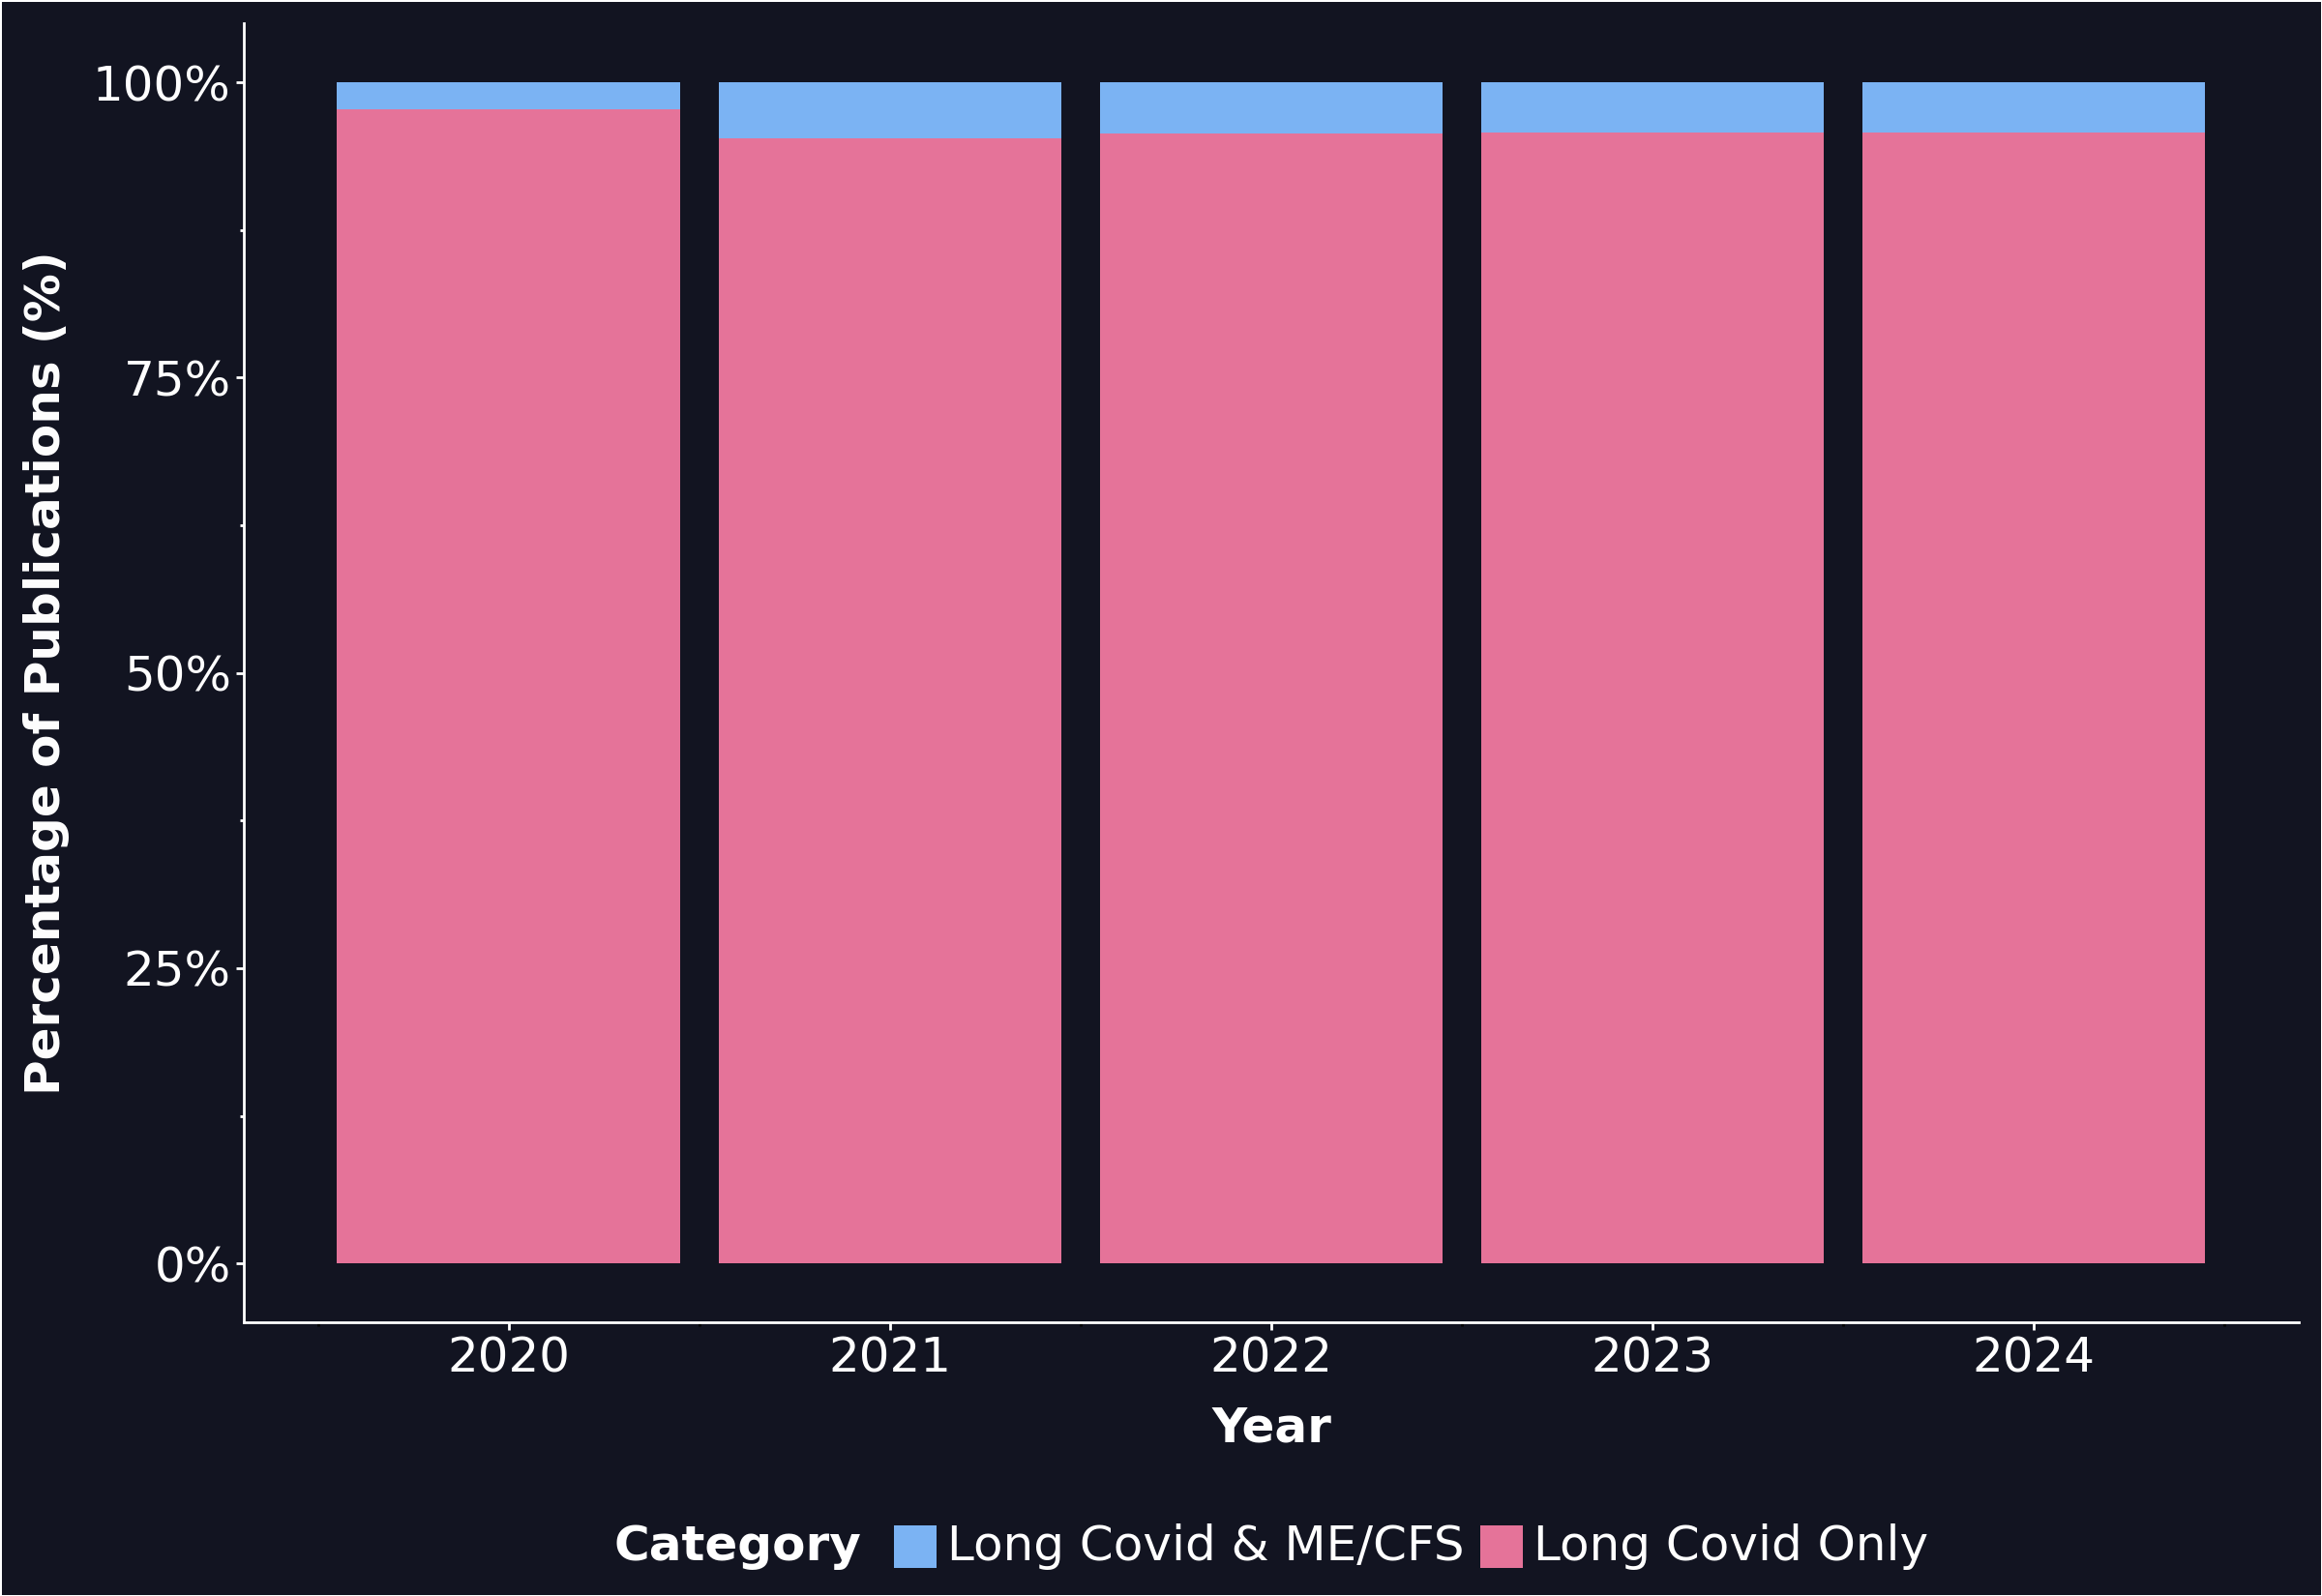

In [ ]:
# Create a percentage stacked bar chart using plotnine
plot = (
    ggplot(long_df, aes(x='Year', y='Percentage', fill='Disease'))
    + geom_bar(stat='identity', position='fill')
    + labs(
        x=None,
        y='Percentage of Publications (%)',
        fill='Category'
    )
    + scale_fill_manual(values=['#7BB3F3', '#E57399'])

    # --- NEW: y-axis as percentage, 0 decimal places ---
    + scale_y_continuous(labels=percent_format(accuracy=1))

    + theme_classic()
    + theme(
        figure_size=(12, 8.25),

        # --- Axis titles ---
        axis_title=element_text(size=18, weight='bold', color='white'),

        # --- UPDATED: axis text size +4 points ---
        axis_text=element_text(size=18, color='white'),

        plot_title=element_text(size=16, weight='bold', color='white', hjust=0),

        legend_title=element_text(size=18, weight='bold', color='white'),
        legend_text=element_text(size=18, color='white'),

        # --- NEW: legend at bottom ---
        legend_position='bottom',
        legend_direction='horizontal',

        plot_background=element_rect(fill='#121421', color=None),
        panel_background=element_rect(fill='#121421', color=None),
        legend_background=element_rect(fill='#121421', color=None),
        legend_key=element_rect(fill='#121421', color=None),

        axis_line=element_line(color='white', size=1),
        axis_ticks=element_line(color='white', size=1)
    )
)

# Display the plot
plot

### ⬇️ 5 | Export Data
---

In [ ]:
# Export dataframe to CSV
long_df.to_csv('long_df.csv', index=False)